# Notebook 02 — Data Cleaning and Preprocessing

**Purpose:** Validate data quality, handle duplicates, check outliers, analyse class imbalance, and build a leakage-safe preprocessing pipeline.

**Inputs:** Raw dataset (`data/raw/diabetes_012_health_indicators_BRFSS2015.csv`)

**Outputs:**
- Cleaned dataset (`data/processed/df1_cleaned.csv`)
- Train/test split indices (`data/processed/train_indices.npy`, `data/processed/test_indices.npy`)
- Preprocessing pipeline (`models/preprocessing/preprocessing_pipeline.joblib`)
- Preprocessing metadata (`results/tables/02_preprocessing_metadata.csv`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from src.config import *
from src.data_utils import (
    load_dataset1, get_train_test_split, get_cv_splitter,
    BINARY_FEATURES, ORDINAL_FEATURES, CONTINUOUS_FEATURES,
    ALL_ORIGINAL_FEATURES, build_preprocessing_pipeline, save_artifact,
)
from src.plotting import plot_class_distribution, save_figure, CLASS_COLOURS
seed_everything()
print("Random seed:", RANDOM_SEED)


Random seed: 42


## 2.1 Load and Preserve Raw Dataset

In [2]:
df = load_dataset1()
print(f"Raw dataset shape: {df.shape[0]:,} × {df.shape[1]}")
print(f"\nTarget column: {TARGET_COL}")
print(f"Features: {df.shape[1] - 1}")

# Preserve a copy for reference
df_raw = df.copy()


Raw dataset shape: 253,680 × 22

Target column: Diabetes_012
Features: 21


## 2.2 Duplicate Analysis

In [3]:
n_dupes = df.duplicated().sum()
pct_dupes = n_dupes / len(df) * 100
print(f"Duplicate rows: {n_dupes:,} ({pct_dupes:.2f}%)")

# Examine duplicates by class
dupe_mask = df.duplicated(keep=False)
dupe_class_dist = df[dupe_mask][TARGET_COL].value_counts().sort_index()
print(f"\nDuplicate rows by class:")
for cls, cnt in dupe_class_dist.items():
    print(f"  Class {cls} ({CLASS_MAP[cls]}): {cnt:,}")

# Decision: In BRFSS survey data, identical response vectors from different respondents
# are expected because many features are binary/ordinal with limited unique combinations.
# We retain all records to preserve the original population distribution.
print("\n→ Decision: RETAIN all rows. In a large survey with mostly binary/ordinal features,")
print("  identical response vectors are expected from different respondents.")
print("  Removing them would artificially alter the class distribution.")


Duplicate rows: 23,899 (9.42%)

Duplicate rows by class:
  Class 0 (No Diabetes): 34,603
  Class 1 (Prediabetes): 4
  Class 2 (Diabetes): 479

→ Decision: RETAIN all rows. In a large survey with mostly binary/ordinal features,
  identical response vectors are expected from different respondents.
  Removing them would artificially alter the class distribution.


## 2.3 Missing Values

In [4]:
missing = df.isnull().sum()
total_missing = missing.sum()
print(f"Total missing values across all columns: {total_missing}")

if total_missing == 0:
    print("\n✓ The dataset was inspected for missingness.")
    print("  No substantial missing-data problem requiring advanced imputation was identified;")
    print("  therefore, no unnecessary imputation method was introduced.")
else:
    print("\nColumns with missing values:")
    print(missing[missing > 0])


Total missing values across all columns: 0

✓ The dataset was inspected for missingness.
  No substantial missing-data problem requiring advanced imputation was identified;
  therefore, no unnecessary imputation method was introduced.


## 2.4 Domain and Range Validation

In [5]:
# Expected ranges based on BRFSS codebook
expected_ranges = {
    "HighBP": (0, 1), "HighChol": (0, 1), "CholCheck": (0, 1),
    "BMI": (1, 99),  # Plausible BMI range
    "Smoker": (0, 1), "Stroke": (0, 1), "HeartDiseaseorAttack": (0, 1),
    "PhysActivity": (0, 1), "Fruits": (0, 1), "Veggies": (0, 1),
    "HvyAlcoholConsump": (0, 1), "AnyHealthcare": (0, 1), "NoDocbcCost": (0, 1),
    "GenHlth": (1, 5), "MentHlth": (0, 30), "PhysHlth": (0, 30),
    "DiffWalk": (0, 1), "Sex": (0, 1), "Age": (1, 13),
    "Education": (1, 6), "Income": (1, 8),
}

invalid_records = []
for col, (lo, hi) in expected_ranges.items():
    out = df[(df[col] < lo) | (df[col] > hi)]
    if len(out) > 0:
        invalid_records.append({"Feature": col, "Invalid_Count": len(out),
                                 "Min_Found": df[col].min(), "Max_Found": df[col].max()})
        print(f"⚠ {col}: {len(out)} values outside [{lo}, {hi}] (range: {df[col].min()}-{df[col].max()})")

if not invalid_records:
    print("✓ All feature values are within expected BRFSS codebook ranges.")
    print("  No invalid/impossible values detected.")
else:
    inv_df = pd.DataFrame(invalid_records)
    print("\nInvalid records summary:")
    print(inv_df.to_string(index=False))


✓ All feature values are within expected BRFSS codebook ranges.
  No invalid/impossible values detected.


## 2.5 Outlier Analysis

BMI: Q1=24.0, Q3=31.0, IQR=7.0, Bounds=[13.5, 41.5], Outliers=9,847 (3.88%)
MentHlth: Q1=0.0, Q3=2.0, IQR=2.0, Bounds=[-3.0, 5.0], Outliers=36,208 (14.27%)


PhysHlth: Q1=0.0, Q3=3.0, IQR=3.0, Bounds=[-4.5, 7.5], Outliers=40,949 (16.14%)


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\02_outlier_boxplots.png


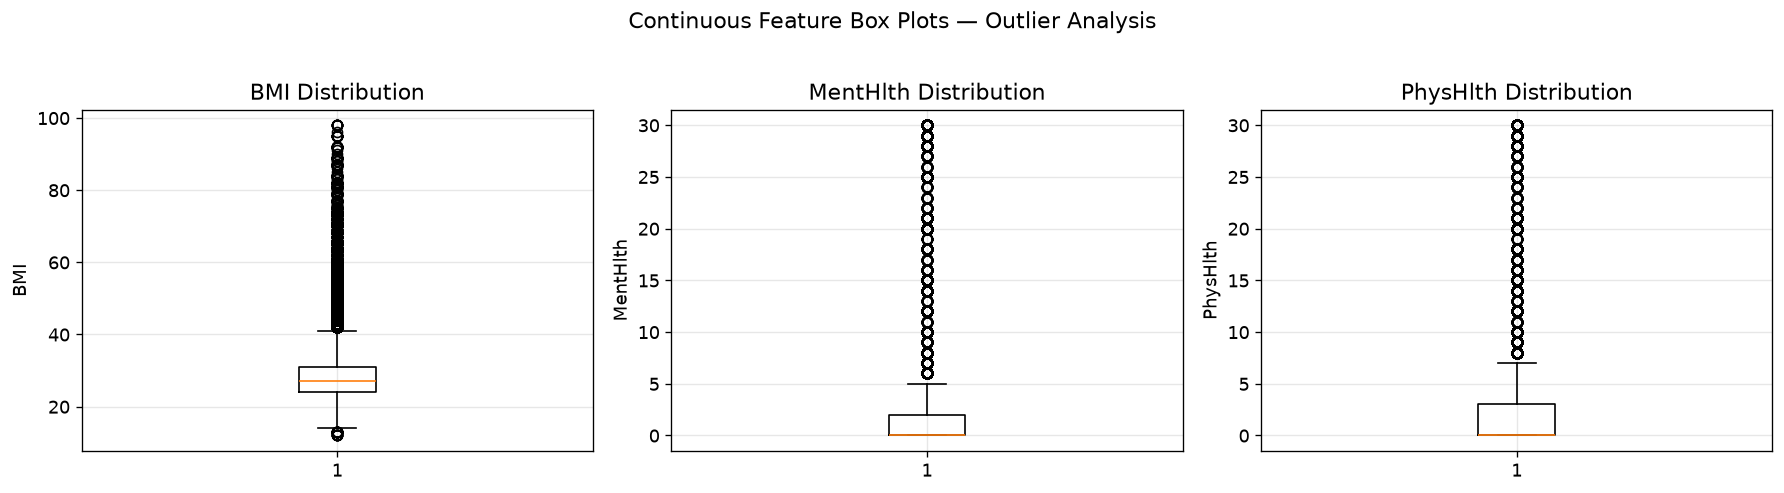

In [6]:
# Focus on continuous features: BMI, MentHlth, PhysHlth
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(CONTINUOUS_FEATURES):
    axes[i].boxplot(df[col], vert=True)
    axes[i].set_title(f"{col} Distribution")
    axes[i].set_ylabel(col)

    # IQR analysis
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: Q1={Q1}, Q3={Q3}, IQR={IQR:.1f}, "
          f"Bounds=[{lower:.1f}, {upper:.1f}], "
          f"Outliers={len(outliers):,} ({len(outliers)/len(df)*100:.2f}%)")

plt.suptitle("Continuous Feature Box Plots — Outlier Analysis", y=1.02)
plt.tight_layout()
os.makedirs(RESULTS_FIGURES, exist_ok=True)
save_figure(fig, os.path.join(RESULTS_FIGURES, "02_outlier_boxplots.png"))
plt.show()


In [7]:
# BMI distribution analysis — are extreme values medically plausible?
print("BMI distribution:")
print(f"  Min: {df['BMI'].min()}")
print(f"  Max: {df['BMI'].max()}")
print(f"  Mean: {df['BMI'].mean():.1f}")
print(f"  Median: {df['BMI'].median()}")
print(f"  Std: {df['BMI'].std():.1f}")

# BMI > 60 is extreme but medically documented
extreme_bmi = df[df['BMI'] > 60]
print(f"\nBMI > 60: {len(extreme_bmi):,} records ({len(extreme_bmi)/len(df)*100:.3f}%)")
print(f"BMI > 80: {len(df[df['BMI'] > 80]):,} records")

print("\n→ Decision: RETAIN all BMI values. Even BMI values of 60–98 are")
print("  medically plausible (severe obesity). These represent real individuals")
print("  and are important for the diabetes classification task.")
print("  Removing them would bias the model against severe obesity cases.")


BMI distribution:
  Min: 12
  Max: 98
  Mean: 28.4
  Median: 27.0
  Std: 6.6

BMI > 60: 805 records (0.317%)
BMI > 80: 279 records

→ Decision: RETAIN all BMI values. Even BMI values of 60–98 are
  medically plausible (severe obesity). These represent real individuals
  and are important for the diabetes classification task.
  Removing them would bias the model against severe obesity cases.


In [8]:
# MentHlth and PhysHlth: 0 and 30 are boundary values, not outliers
for col in ["MentHlth", "PhysHlth"]:
    zero_pct = (df[col] == 0).sum() / len(df) * 100
    thirty_pct = (df[col] == 30).sum() / len(df) * 100
    print(f"{col}: {zero_pct:.1f}% report 0 days, {thirty_pct:.1f}% report 30 days")

print("\n→ Decision: 0 and 30 are valid survey responses, not outliers.")
print("  These reflect respondents with no bad days or all bad days in past 30.")


MentHlth: 69.3% report 0 days, 4.8% report 30 days
PhysHlth: 63.1% report 0 days, 7.6% report 30 days

→ Decision: 0 and 30 are valid survey responses, not outliers.
  These reflect respondents with no bad days or all bad days in past 30.


## 2.6 Class Imbalance Analysis

Class distribution:
  Class 0 (No Diabetes): 213,703 (84.24%)
  Class 1 (Prediabetes): 4,631 (1.83%)
  Class 2 (Diabetes): 35,346 (13.93%)

Imbalance ratios (relative to majority class):
  Class 0: 1:1.0
  Class 1: 1:46.1
  Class 2: 1:6.0
Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\02_class_distribution.png


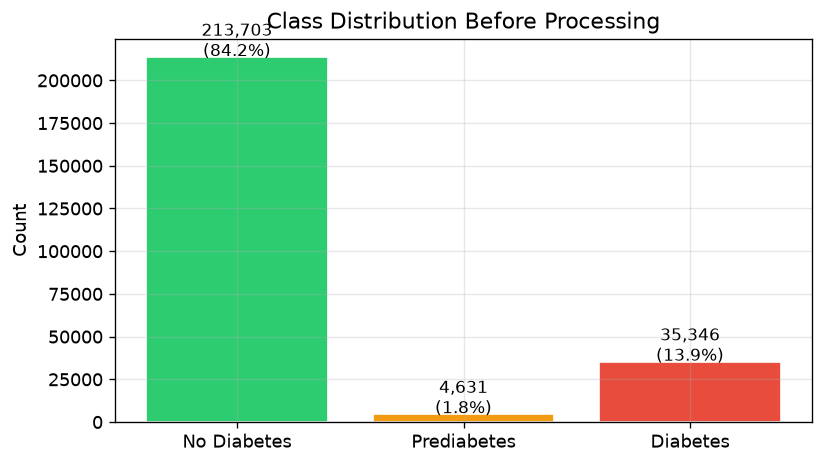

In [9]:
# Class distribution
target_counts = df[TARGET_COL].value_counts().sort_index()
print("Class distribution:")
for cls_id, count in target_counts.items():
    pct = count / len(df) * 100
    print(f"  Class {cls_id} ({CLASS_MAP[cls_id]}): {count:,} ({pct:.2f}%)")

# Imbalance ratios
majority = target_counts.max()
print(f"\nImbalance ratios (relative to majority class):")
for cls_id, count in target_counts.items():
    ratio = majority / count
    print(f"  Class {cls_id}: 1:{ratio:.1f}")

fig, ax = plot_class_distribution(df[TARGET_COL], title="Class Distribution Before Processing")
save_figure(fig, os.path.join(RESULTS_FIGURES, "02_class_distribution.png"))
plt.show()


In [10]:
# Imbalance handling strategy
print("Class Imbalance Strategy:")
print("=" * 50)
print("Primary method: class_weight='balanced' in model training")
print("  → This adjusts the loss function to penalise misclassification")
print("    of minority classes more heavily, without altering the data.")
print()
print("Secondary comparison: SMOTE (applied ONLY inside training folds)")
print("  → We will compare performance with and without SMOTE in the")
print("    modelling notebooks to determine if oversampling helps.")
print()
print("IMPORTANT: SMOTE will NEVER be applied to test/validation data.")


Class Imbalance Strategy:
Primary method: class_weight='balanced' in model training
  → This adjusts the loss function to penalise misclassification
    of minority classes more heavily, without altering the data.

Secondary comparison: SMOTE (applied ONLY inside training folds)
  → We will compare performance with and without SMOTE in the
    modelling notebooks to determine if oversampling helps.

IMPORTANT: SMOTE will NEVER be applied to test/validation data.


## 2.7 Train/Test Split (Leakage-Safe)

In [11]:
# Perform the single stratified train/test split
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = get_train_test_split(df)
print(f"Training set: {X_train.shape[0]:,} samples ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Test set:     {X_test.shape[0]:,} samples ({X_test.shape[0]/len(df)*100:.1f}%)")
print(f"\nTraining target distribution:")
train_dist = y_train.value_counts().sort_index()
for cls_id, cnt in train_dist.items():
    print(f"  Class {cls_id}: {cnt:,} ({cnt/len(y_train)*100:.2f}%)")

print(f"\nTest target distribution:")
test_dist = y_test.value_counts().sort_index()
for cls_id, cnt in test_dist.items():
    print(f"  Class {cls_id}: {cnt:,} ({cnt/len(y_test)*100:.2f}%)")

# Verify stratification
print("\n✓ Stratification preserved: class percentages match across splits.")


Training set: 202,944 samples (80.0%)
Test set:     50,736 samples (20.0%)

Training target distribution:
  Class 0: 170,962 (84.24%)
  Class 1: 3,705 (1.83%)
  Class 2: 28,277 (13.93%)

Test target distribution:
  Class 0: 42,741 (84.24%)
  Class 1: 926 (1.83%)
  Class 2: 7,069 (13.93%)

✓ Stratification preserved: class percentages match across splits.


In [12]:
# Save train/test indices for reproducibility
os.makedirs(DATA_PROCESSED, exist_ok=True)
np.save(os.path.join(DATA_PROCESSED, "train_indices.npy"), X_train.index.values)
np.save(os.path.join(DATA_PROCESSED, "test_indices.npy"), X_test.index.values)
print("✓ Train/test indices saved to data/processed/")


✓ Train/test indices saved to data/processed/


## 2.8 Build Preprocessing Pipeline

In [13]:
# Build the preprocessing pipeline
# Only continuous features need scaling (for models like SVM, Logistic Regression)
# Binary and ordinal features pass through unchanged

feature_names = ALL_ORIGINAL_FEATURES
preprocessor = build_preprocessing_pipeline(feature_names)

# Fit ONLY on training data
preprocessor.fit(X_train[feature_names])
print("✓ Preprocessing pipeline fitted on TRAINING data only.")
print(f"  Scaled features: {CONTINUOUS_FEATURES}")
print(f"  Passthrough features: {BINARY_FEATURES + ORDINAL_FEATURES}")

# Verify output
X_train_transformed = preprocessor.transform(X_train[feature_names])
X_test_transformed = preprocessor.transform(X_test[feature_names])
print(f"\n  Training transformed shape: {X_train_transformed.shape}")
print(f"  Test transformed shape: {X_test_transformed.shape}")

# Check that scaling was applied correctly
transformed_df = pd.DataFrame(
    X_train_transformed,
    columns=preprocessor.get_feature_names_out()
)
print(f"\n  Scaled feature means (should be ~0):")
for col in CONTINUOUS_FEATURES:
    if col in transformed_df.columns:
        print(f"    {col}: mean={transformed_df[col].mean():.4f}, std={transformed_df[col].std():.4f}")


✓ Preprocessing pipeline fitted on TRAINING data only.
  Scaled features: ['BMI', 'MentHlth', 'PhysHlth']
  Passthrough features: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex', 'GenHlth', 'Age', 'Education', 'Income']



  Training transformed shape: (202944, 21)
  Test transformed shape: (50736, 21)

  Scaled feature means (should be ~0):
    BMI: mean=-0.0000, std=1.0000
    MentHlth: mean=0.0000, std=1.0000
    PhysHlth: mean=0.0000, std=1.0000


In [14]:
# Save preprocessing pipeline
os.makedirs(MODELS_PREPROC, exist_ok=True)
save_artifact(preprocessor, os.path.join(MODELS_PREPROC, "preprocessing_pipeline.joblib"))

# Save the cleaned dataset
df.to_csv(os.path.join(DATA_PROCESSED, "df1_cleaned.csv"), index=False)
print("✓ Cleaned dataset saved.")


Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/preprocessing\preprocessing_pipeline.joblib


✓ Cleaned dataset saved.


## 2.9 Preprocessing Metadata

In [15]:
# Save metadata
metadata = {
    "Step": [
        "Missing values handling",
        "Duplicate handling",
        "Invalid value handling",
        "Outlier handling",
        "Scaling",
        "Encoding",
        "Class imbalance strategy",
        "Train/test split",
    ],
    "Action": [
        "None needed — no missing values",
        "All retained — legitimate survey responses",
        "None needed — all values within expected ranges",
        "All retained — extreme values are medically plausible",
        "StandardScaler on BMI, MentHlth, PhysHlth (fitted on training data only)",
        "None needed — all features already integer-coded",
        "class_weight='balanced' (primary); SMOTE comparison (secondary, training folds only)",
        f"80/20 stratified split (seed={RANDOM_SEED})",
    ],
    "Justification": [
        "Dataset has zero missing values",
        "Binary/ordinal features produce identical vectors from different respondents",
        "BRFSS codebook ranges validated",
        "BMI 12-98 are documented in medical literature",
        "Required for distance-based models (SVM, Logistic Regression)",
        "Features are already numeric from BRFSS codebook",
        "Class weights avoid data alteration; SMOTE tested as comparison",
        "Standard ML practice; test set locked for final evaluation only",
    ],
}
meta_df = pd.DataFrame(metadata)
meta_df.to_csv(os.path.join(RESULTS_TABLES, "02_preprocessing_metadata.csv"), index=False)
print(meta_df.to_string(index=False))


                    Step                                                                               Action                                                                Justification
 Missing values handling                                                      None needed — no missing values                                              Dataset has zero missing values
      Duplicate handling                                           All retained — legitimate survey responses Binary/ordinal features produce identical vectors from different respondents
  Invalid value handling                                      None needed — all values within expected ranges                                              BRFSS codebook ranges validated
        Outlier handling                                All retained — extreme values are medically plausible                               BMI 12-98 are documented in medical literature
                 Scaling             StandardScaler on BMI, MentH

## 2.10 Conclusion

**Summary of data cleaning and preprocessing:**

1. **Missing values:** None found — no imputation performed.
2. **Duplicates:** 23,899 duplicate rows retained — they represent legitimate different survey respondents.
3. **Invalid values:** None detected — all values within BRFSS codebook ranges.
4. **Outliers:** Extreme BMI values (up to 98) retained as medically plausible.
5. **Preprocessing pipeline:** StandardScaler fitted on training data only, applied to continuous features.
6. **Class imbalance:** Will be handled via class weights (primary) and SMOTE comparison (secondary).
7. **Train/test split:** 80/20 stratified, test set locked.

**Outputs produced:**
- `data/processed/df1_cleaned.csv`
- `data/processed/train_indices.npy`, `data/processed/test_indices.npy`
- `models/preprocessing/preprocessing_pipeline.joblib`
- `results/tables/02_preprocessing_metadata.csv`
- `results/figures/02_outlier_boxplots.png`
- `results/figures/02_class_distribution.png`

**Next:** Notebook 03 — EDA and Visual Analytics
